# Part II: PyTorch CNN

This notebook inspects the prescribed reduced VGG, loads recorded experiments, and plots loss and accuracy. All prose and figures must be interpreted using the displayed dataset sizes and run scope.

The baseline uses eight Conv2d–BatchNorm2d–ReLU blocks, five specified max pools, and Linear(512, 10). Adam uses learning rate 0.001 and its remaining defaults. Inputs are converted to tensors and normalized with per-channel mean and standard deviation 0.5. Reported split metrics use evaluation mode and sample-weighted means.

Training is opt-in in the cell below. Normal execution reads saved results.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import matplotlib.pyplot as plt
import torch
from IPython.display import display, Markdown

# Support execution from either the assignment root or Part 2.
PART_DIR = Path.cwd().resolve()
if not (PART_DIR / "cnn_model.py").is_file():
    PART_DIR = PART_DIR / "Part 2"
if not (PART_DIR / "cnn_model.py").is_file():
    raise FileNotFoundError("Open this notebook from assignment2 or Part 2.")
sys.path.insert(0, str(PART_DIR))
from cnn_model import CNN
from cnn_train import train

torch.set_num_threads(1)
RUN_TRAINING = False
# Set a specific run folder to compare or revisit a previous experiment.
RUN_DIR = None



Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	<user-home>/.cache/fontconfig
	<user-home>/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	<user-home>/.cache/fontconfig
	<user-home>/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	<user-home>/.cache/fontconfig
	<user-home>/.fontconfig



Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	<user-home>/.cache/fontconfig
	<user-home>/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	<user-home>/.cache/fontconfig
	<user-home>/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	<user-home>/.cache/fontconfig
	<user-home>/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	<user-home>/.cache/fontconfig
	<user-home>/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	<user-home>/.cache/fontconfig
	<user-home>/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	<user-home>/.cache/fontconfig
	<user-home>/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	<user-home>/.cache/fontconfig
	<user-home>/.fontconfig

Fontconfig e

Matplotlib is building the font cache; this may take a moment.


/opt/homebrew/Caskroom/miniconda/base/envs/mldl/lib/python3.11/site-packages/torchvision/io/image.py:14: UserWarning: Failed to load image Python extension: 'dlopen(/opt/homebrew/Caskroom/miniconda/base/envs/mldl/lib/python3.11/site-packages/torchvision/image.so, 0x0006): Library not loaded: @rpath/libjpeg.9.dylib
  Referenced from: <EB3FF92A-5EB1-3EE8-AF8B-5923C1265422> /opt/homebrew/Caskroom/miniconda/base/envs/mldl/lib/python3.11/site-packages/torchvision/image.so
  Reason: tried: '/opt/homebrew/Caskroom/miniconda/base/envs/mldl/lib/python3.11/site-packages/torchvision/../../../libjpeg.9.dylib' (no such file), '/opt/homebrew/Caskroom/miniconda/base/envs/mldl/lib/python3.11/site-packages/torchvision/../../../libjpeg.9.dylib' (no such file), '/opt/homebrew/Caskroom/miniconda/base/envs/mldl/lib/python3.11/lib-dynload/../../libjpeg.9.dylib' (no such file), '/opt/homebrew/Caskroom/miniconda/base/envs/mldl/bin/../lib/libjpeg.9.dylib' (no such file)'If you don't plan on using image functio

## Task 1: architecture and tensor dimensions

For each convolution, the weight shape is `(out_channels, in_channels, 3, 3)`. BatchNorm has a trainable scale and bias for each output channel. Running statistics are buffers. The following table is generated by executing each layer with a batch of two images.

In [2]:
with torch.random.fork_rng():
    torch.manual_seed(42)
    inspection_model = CNN().eval()

rows = []
value = torch.zeros(2, 3, 32, 32)
with torch.no_grad():
    for index, layer in enumerate(inspection_model.features):
        input_shape = tuple(value.shape)
        value = layer(value)
        weights = "; ".join(
            f"{name} {tuple(parameter.shape)}"
            for name, parameter in layer.named_parameters(recurse=False)
        ) or "—"
        count = sum(parameter.numel() for parameter in layer.parameters())
        rows.append((str(index), type(layer).__name__, str(input_shape),
                     str(tuple(value.shape)), weights, str(count)))
    input_shape = tuple(value.shape)
    value = value.flatten(1)
    rows.append(("flatten", "Flatten", str(input_shape), str(tuple(value.shape)), "—", "0"))
    logits = inspection_model.classifier(value)
    rows.append(("classifier", "Linear", str(tuple(value.shape)), str(tuple(logits.shape)),
                 "weight (10, 512); bias (10,)", "5130"))

header = "| Layer | Operation | Input | Output | Parameters | Count |\n|---|---|---|---|---|---|\n"
display(Markdown(header + "\n".join("| " + " | ".join(row) + " |" for row in rows)))
parameter_count = sum(p.numel() for p in inspection_model.parameters())
assert parameter_count == 9_231_114
print(f"Total trainable parameters: {parameter_count:,}")
del inspection_model


| Layer | Operation | Input | Output | Parameters | Count |
|---|---|---|---|---|---|
| 0 | Conv2d | (2, 3, 32, 32) | (2, 64, 32, 32) | weight (64, 3, 3, 3); bias (64,) | 1792 |
| 1 | BatchNorm2d | (2, 64, 32, 32) | (2, 64, 32, 32) | weight (64,); bias (64,) | 128 |
| 2 | ReLU | (2, 64, 32, 32) | (2, 64, 32, 32) | — | 0 |
| 3 | MaxPool2d | (2, 64, 32, 32) | (2, 64, 16, 16) | — | 0 |
| 4 | Conv2d | (2, 64, 16, 16) | (2, 128, 16, 16) | weight (128, 64, 3, 3); bias (128,) | 73856 |
| 5 | BatchNorm2d | (2, 128, 16, 16) | (2, 128, 16, 16) | weight (128,); bias (128,) | 256 |
| 6 | ReLU | (2, 128, 16, 16) | (2, 128, 16, 16) | — | 0 |
| 7 | MaxPool2d | (2, 128, 16, 16) | (2, 128, 8, 8) | — | 0 |
| 8 | Conv2d | (2, 128, 8, 8) | (2, 256, 8, 8) | weight (256, 128, 3, 3); bias (256,) | 295168 |
| 9 | BatchNorm2d | (2, 256, 8, 8) | (2, 256, 8, 8) | weight (256,); bias (256,) | 512 |
| 10 | ReLU | (2, 256, 8, 8) | (2, 256, 8, 8) | — | 0 |
| 11 | Conv2d | (2, 256, 8, 8) | (2, 256, 8, 8) | weight (256, 256, 3, 3); bias (256,) | 590080 |
| 12 | BatchNorm2d | (2, 256, 8, 8) | (2, 256, 8, 8) | weight (256,); bias (256,) | 512 |
| 13 | ReLU | (2, 256, 8, 8) | (2, 256, 8, 8) | — | 0 |
| 14 | MaxPool2d | (2, 256, 8, 8) | (2, 256, 4, 4) | — | 0 |
| 15 | Conv2d | (2, 256, 4, 4) | (2, 512, 4, 4) | weight (512, 256, 3, 3); bias (512,) | 1180160 |
| 16 | BatchNorm2d | (2, 512, 4, 4) | (2, 512, 4, 4) | weight (512,); bias (512,) | 1024 |
| 17 | ReLU | (2, 512, 4, 4) | (2, 512, 4, 4) | — | 0 |
| 18 | Conv2d | (2, 512, 4, 4) | (2, 512, 4, 4) | weight (512, 512, 3, 3); bias (512,) | 2359808 |
| 19 | BatchNorm2d | (2, 512, 4, 4) | (2, 512, 4, 4) | weight (512,); bias (512,) | 1024 |
| 20 | ReLU | (2, 512, 4, 4) | (2, 512, 4, 4) | — | 0 |
| 21 | MaxPool2d | (2, 512, 4, 4) | (2, 512, 2, 2) | — | 0 |
| 22 | Conv2d | (2, 512, 2, 2) | (2, 512, 2, 2) | weight (512, 512, 3, 3); bias (512,) | 2359808 |
| 23 | BatchNorm2d | (2, 512, 2, 2) | (2, 512, 2, 2) | weight (512,); bias (512,) | 1024 |
| 24 | ReLU | (2, 512, 2, 2) | (2, 512, 2, 2) | — | 0 |
| 25 | Conv2d | (2, 512, 2, 2) | (2, 512, 2, 2) | weight (512, 512, 3, 3); bias (512,) | 2359808 |
| 26 | BatchNorm2d | (2, 512, 2, 2) | (2, 512, 2, 2) | weight (512,); bias (512,) | 1024 |
| 27 | ReLU | (2, 512, 2, 2) | (2, 512, 2, 2) | — | 0 |
| 28 | MaxPool2d | (2, 512, 2, 2) | (2, 512, 1, 1) | — | 0 |
| flatten | Flatten | (2, 512, 1, 1) | (2, 512) | — | 0 |
| classifier | Linear | (2, 512) | (2, 10) | weight (10, 512); bias (10,) | 5130 |

Total trainable parameters: 9,231,114


## Optional full-data training

Enable `RUN_TRAINING` only when ready to run 5,000 updates and periodic full-split evaluation. Each invocation creates a unique output folder. CPU is the explicit default here; select MPS or CUDA only when available in your execution environment. A fixed seed controls initialization and shuffling, while backend-dependent numerical behavior can still differ.

In [3]:
if RUN_TRAINING:
    model, training_history = train(
        data_dir=PART_DIR.parent / "data",
        batch_size=32,
        max_steps=5000,
        eval_freq=500,
        learning_rate=0.001,
        seed=42,
        device="cpu",
        download=False,
        output_dir=PART_DIR / "results" / "cnn",
    )


## Task 2: recorded results

Selection prefers the latest full-data run under `results/cnn`. If none exists, the notebook displays the explicitly labelled CPU smoke run under `results/smoke/cpu`. Set `RUN_DIR` above to select a particular run. An interrupted run can be inspected using its most recently saved evaluation.

In [4]:
if RUN_DIR is None:
    candidates = sorted((PART_DIR / "results" / "cnn").glob("*/history.json"))
    if not candidates:
        candidates = sorted((PART_DIR / "results" / "smoke" / "cpu").glob("*/history.json"))
    if not candidates:
        raise FileNotFoundError("No saved history found. Run training or select an existing RUN_DIR.")
    run_dir = candidates[-1].parent
else:
    run_dir = Path(RUN_DIR).expanduser().resolve()

record = json.loads((run_dir / "history.json").read_text())
history = record["history"]
config = record["config"]
smoke = config.get("scope") == "smoke"
label = "CIFAR10 subset smoke test" if smoke else "CIFAR10 experiment"
print("Run folder:", run_dir)
print("Scope:", label)
print("Status:", record["status"])
print("Configuration:", json.dumps(config, indent=2))
print("Dataset sizes:", {key: record[key] for key in
                         ("train_examples", "train_eval_examples", "test_examples")})
if smoke:
    display(Markdown("**This short subset run verifies the training pipeline. Generalization and convergence remain unassessed.**"))

rows = ["| Update | Examples seen | Epoch equivalent | Train loss | Test loss | Train accuracy | Test accuracy |",
        "|---|---|---|---|---|---|---|"]
for i, step in enumerate(history["steps"]):
    rows.append(
        f"| {step} | {history['samples_seen'][i]} | {history['epoch_equivalent'][i]:.3f} | "
        f"{history['train_loss'][i]:.4f} | {history['test_loss'][i]:.4f} | "
        f"{history['train_accuracy'][i]:.2%} | {history['test_accuracy'][i]:.2%} |"
    )
display(Markdown("\n".join(rows)))


Run folder: <assignment-root>/Part 2/results/smoke/cpu/20261119T005947Z-_ol4ibym
Scope: CIFAR10 subset smoke test
Status: complete
Configuration: {
  "scope": "smoke",
  "data_dir": "<assignment-root>/data",
  "device": "cpu",
  "seed": 42,
  "batch_size": 4,
  "max_steps": 6,
  "eval_freq": 2,
  "learning_rate": 0.001,
  "train_indices": [
    0,
    1,
    2,
    3,
    4,
    5,
    6,
    7,
    8,
    9,
    10,
    11,
    12,
    13,
    14,
    15
  ],
  "test_indices": [
    0,
    1,
    2,
    3,
    4,
    5,
    6,
    7
  ],
  "cpu_threads": 1
}
Dataset sizes: {'train_examples': 16, 'train_eval_examples': 16, 'test_examples': 8}


**This short subset run verifies the training pipeline. Generalization and convergence remain unassessed.**

| Update | Examples seen | Epoch equivalent | Train loss | Test loss | Train accuracy | Test accuracy |
|---|---|---|---|---|---|---|
| 2 | 8 | 0.500 | 2.2815 | 2.3259 | 25.00% | 0.00% |
| 4 | 16 | 1.000 | 2.1824 | 2.3054 | 12.50% | 12.50% |
| 6 | 24 | 1.500 | 2.1870 | 2.5975 | 12.50% | 12.50% |

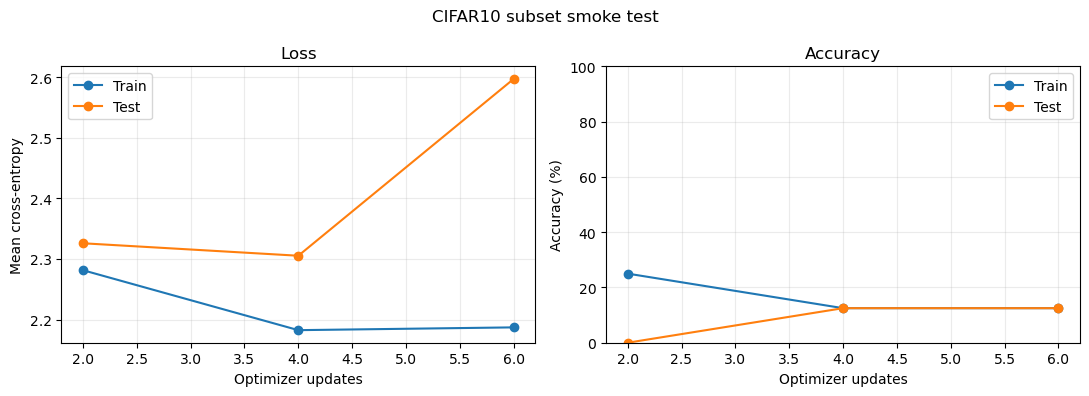

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for split, color in (("train", "tab:blue"), ("test", "tab:orange")):
    axes[0].plot(history["steps"], history[f"{split}_loss"],
                 marker="o", label=split.capitalize(), color=color)
    axes[1].plot(history["steps"], 100 * np.asarray(history[f"{split}_accuracy"]),
                 marker="o", label=split.capitalize(), color=color)
axes[0].set(xlabel="Optimizer updates", ylabel="Mean cross-entropy", title="Loss")
axes[1].set(xlabel="Optimizer updates", ylabel="Accuracy (%)", title="Accuracy", ylim=(0, 100))
for axis in axes:
    axis.legend()
    axis.grid(alpha=0.25)
fig.suptitle(label)
fig.tight_layout()
fig.savefig(run_dir / "learning_curves.png", dpi=180)
plt.show()


In [6]:
train_acc = history["train_accuracy"][-1]
test_acc = history["test_accuracy"][-1]
gap = 100 * (train_acc - test_acc)
loss_change = history["test_loss"][-1] - history["test_loss"][0]
display(Markdown(
    f"The last saved model follows **{history['steps'][-1]} updates** and "
    f"**{history['samples_seen'][-1]} processed training examples**. "
    f"Its train accuracy is **{train_acc:.2%}** and test accuracy is **{test_acc:.2%}**, "
    f"a signed train-minus-test gap of **{gap:.2f} percentage points**. "
    f"Test loss changed by **{loss_change:+.4f}** between the first and last saved evaluations."
))
if smoke:
    display(Markdown(
        "The evaluation sets are small fixed subsets and the update budget is deliberately short. "
        "These observations establish that data loading, optimization, evaluation, and persistence execute. "
        "They do not establish model convergence, a useful CIFAR10 accuracy, or an overfitting trend."
    ))
else:
    display(Markdown(
        "For the report, examine whether the final loss is still decreasing, whether the train/test "
        "gap grows across updates, and how much data the model has processed. A single seed and "
        "descriptive test curves provide limited evidence for broad performance claims. "
        "Use a validation split for subsequent hyperparameter selection."
    ))


The last saved model follows **6 updates** and **24 processed training examples**. Its train accuracy is **12.50%** and test accuracy is **12.50%**, a signed train-minus-test gap of **0.00 percentage points**. Test loss changed by **+0.2715** between the first and last saved evaluations.

The evaluation sets are small fixed subsets and the update budget is deliberately short. These observations establish that data loading, optimization, evaluation, and persistence execute. They do not establish model convergence, a useful CIFAR10 accuracy, or an overfitting trend.

## Saved artifacts and recovery scope

Each run has its own directory. `config.json` records the requested settings. At each evaluation, `checkpoint.pt` stores model parameters, BatchNorm buffers, Adam state, update count, sample count, and metric history. `history.json` is the plotting export. `model.pt` is written after the final update for inference.

Files are replaced atomically within a run. The checkpoint is authoritative if a process stops between checkpoint and JSON writes. Checkpoints preserve learned state for recovery; exact interrupted-trajectory continuation would additionally require the data-iterator position and RNG states, and is not implemented here. Use `torch.load(path, map_location="cpu", weights_only=True)` to inspect a checkpoint from this project.

The final report must include layer parameters and shapes, the forward/loss/backward/update procedure, quantitative results, and figure-based analysis. A complete scientific interpretation requires the full experiment results.